In [1]:
import numpy as np
%pip install lime
import lime
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools
from datasets import concatenate_datasets

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   -------------------------------------- - 11.5/12.0 MB 62.8 MB/s eta 0:00:01
   ---------------------------------------- 12.0/12.0 MB 51.7 MB/s  0:00:00
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=284307 sha256=0ab6f84bef74a320fe65447476dc3587dd0080d6be54027623494d2debb35119
  Stored in directory: c:\users\stanv\appdata\local\pip\cache\wheels\eb\51\d9\c707b8fa7dee923cf3cb03edaf5c7f2bfeed5b91f5ca72f468
Successfully built lime

   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   ---------------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from datasets import load_dataset, concatenate_datasets, DatasetDict

topics = ["stance_abortion", "stance_atheism", "stance_climate", "stance_feminist", "stance_hillary"]

per_topic = [load_dataset("cardiffnlp/tweet_eval", t) for t in topics]

# all topics
dataset = DatasetDict({
    split: concatenate_datasets([ds[split] for ds in per_topic])
    for split in ["train", "validation", "test"]
})
# 1 topic
# dataset = per_topic[0]

dataset = dataset.map(lambda x: {"text": x["text"].replace(" #SemST", "")})
# 1 topic
# dataset = load_dataset("cardiffnlp/tweet_eval", topics[0])

Map:   0%|          | 0/2620 [00:00<?, ? examples/s]

Map:   0%|          | 0/294 [00:00<?, ? examples/s]

Map:   0%|          | 0/1249 [00:00<?, ? examples/s]

In [3]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [4]:
#tokenizer
vocab_size = 1000
min_frequency = 2
comb_dataset = concatenate_datasets([dataset["train"], dataset["validation"]])
corpus = [text for text in comb_dataset["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [5]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(comb_dataset["text"], comb_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [6]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [7]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [8]:
outcome_space = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [9]:
classifiers = OrderedDict()

In [10]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [11]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: '

In [ ]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.693 seconds
Dataloader done! Time taken: 0.033 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

c:\Users\stanv\OneDrive\Documents\NLP1\Project1\smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
c:\Users\stanv\OneDrive\Documents\NLP1\Project1\smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 1.0432 | train acc: 0.4728 | val loss: 1.0117 | val acc: 0.4768
Training done! Time taken: 2.963 seconds
Transforming documents...
Document transformation done! Time taken: 0.873 seconds
Dataloader done! Time taken: 0.035 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0504 | train acc: 0.4487 | val loss: 1.0223 | val acc: 0.4648
Training done! Time taken: 0.342 seconds
Transforming documents...
Document transformation done! Time taken: 0.713 seconds
Dataloader done! Time taken: 0.026 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0441 | train acc: 0.4571 | val loss: 1.0162 | val acc: 0.4691
Training done! Time taken: 0.375 seconds


In [ ]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.772 seconds
Dataloader done! Time taken: 0.035 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0515 | train acc: 0.4629 | val loss: 1.0280 | val acc: 0.4751
Training done! Time taken: 0.493 seconds
Transforming documents...
Document transformation done! Time taken: 0.772 seconds
Dataloader done! Time taken: 0.027 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0502 | train acc: 0.4719 | val loss: 1.0057 | val acc: 0.5026
Training done! Time taken: 0.457 seconds
Transforming documents...
Document transformation done! Time taken: 0.786 seconds
Dataloader done! Time taken: 0.032 seconds
Training...


... (2 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0508 | train acc: 0.4595 | val loss: 1.0250 | val acc: 0.4648
Training done! Time taken: 0.410 seconds
Transforming documents...
Document transformation done! Time taken: 0.726 seconds
Dataloader done! Time taken: 0.025 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0445 | train acc: 0.4781 | val loss: 1.0279 | val acc: 0.4691
Training done! Time taken: 0.475 seconds


In [14]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: '

In [ ]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.669 seconds
Dataloader done! Time taken: 0.026 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0469 | train acc: 0.4590 | val loss: 1.0176 | val acc: 0.4768
Training done! Time taken: 0.496 seconds
Transforming documents...
Document transformation done! Time taken: 0.775 seconds
Dataloader done! Time taken: 0.024 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0534 | train acc: 0.4449 | val loss: 0.9992 | val acc: 0.5043
Training done! Time taken: 0.411 seconds
Transforming documents...
Document transformation done! Time taken: 0.720 seconds
Dataloader done! Time taken: 0.025 seconds
Training...


... (2 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0429 | train acc: 0.4586 | val loss: 1.0144 | val acc: 0.4666
Training done! Time taken: 0.465 seconds
Transforming documents...
Document transformation done! Time taken: 0.721 seconds
Dataloader done! Time taken: 0.022 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0471 | train acc: 0.4713 | val loss: 1.0153 | val acc: 0.4691
Training done! Time taken: 0.367 seconds


In [ ]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.746 seconds
Dataloader done! Time taken: 0.025 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0484 | train acc: 0.4710 | val loss: 1.0345 | val acc: 0.4751
Training done! Time taken: 0.420 seconds
Transforming documents...
Document transformation done! Time taken: 0.854 seconds
Dataloader done! Time taken: 0.022 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0501 | train acc: 0.4672 | val loss: 1.0041 | val acc: 0.5026
Training done! Time taken: 0.521 seconds
Transforming documents...
Document transformation done! Time taken: 0.779 seconds
Dataloader done! Time taken: 0.027 seconds
Training...


... (2 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0469 | train acc: 0.4680 | val loss: 1.0303 | val acc: 0.4648
Training done! Time taken: 0.487 seconds
Transforming documents...
Document transformation done! Time taken: 0.848 seconds
Dataloader done! Time taken: 0.023 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0434 | train acc: 0.4777 | val loss: 1.0276 | val acc: 0.4691
Training done! Time taken: 0.527 seconds


In [17]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nl

In [ ]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf(tokenizer),
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.723 seconds
Dataloader done! Time taken: 0.039 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0679 | train acc: 0.4702 | val loss: 1.0459 | val acc: 0.4751
Training done! Time taken: 0.459 seconds
Transforming documents...
Document transformation done! Time taken: 0.810 seconds
Dataloader done! Time taken: 0.026 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0863 | train acc: 0.3938 | val loss: 1.0387 | val acc: 0.5026
Training done! Time taken: 0.417 seconds
Transforming documents...
Document transformation done! Time taken: 0.826 seconds
Dataloader done! Time taken: 0.025 seconds
Training...


... (2 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0641 | train acc: 0.4822 | val loss: 1.0522 | val acc: 0.4648
Training done! Time taken: 0.480 seconds
Transforming documents...
Document transformation done! Time taken: 0.767 seconds
Dataloader done! Time taken: 0.026 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0722 | train acc: 0.4310 | val loss: 1.0505 | val acc: 0.4691
Training done! Time taken: 0.413 seconds


In [ ]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.794 seconds
Dataloader done! Time taken: 0.023 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0509 | train acc: 0.4543 | val loss: 1.0258 | val acc: 0.4751
Training done! Time taken: 0.455 seconds
Transforming documents...
Document transformation done! Time taken: 0.759 seconds
Dataloader done! Time taken: 0.023 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0533 | train acc: 0.4616 | val loss: 1.0041 | val acc: 0.5026
Training done! Time taken: 0.425 seconds
Transforming documents...
Document transformation done! Time taken: 0.726 seconds
Dataloader done! Time taken: 0.027 seconds
Training...


... (2 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0497 | train acc: 0.4620 | val loss: 1.0328 | val acc: 0.4648
Training done! Time taken: 0.417 seconds
Transforming documents...
Document transformation done! Time taken: 0.770 seconds
Dataloader done! Time taken: 0.022 seconds
Training...


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0547 | train acc: 0.4584 | val loss: 1.0303 | val acc: 0.4691
Training done! Time taken: 0.437 seconds


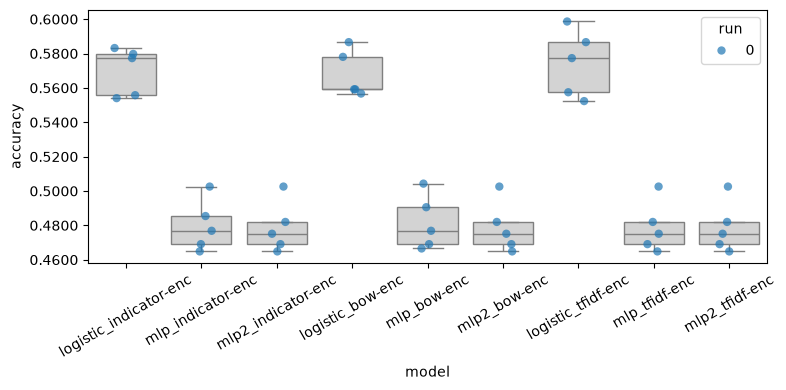

In [20]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [21]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.9962
P(Tie)    = 0.0013
P(B wins) = 0.0026
Effect Size = -5.25

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.9963
P(Tie)    = 0.0012
P(B wins) = 0.0025
Effect Size = -5.29

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.0091
P(Tie)    = 0.9888
P(B wins) = 0.0021
Effect Size = -1.00


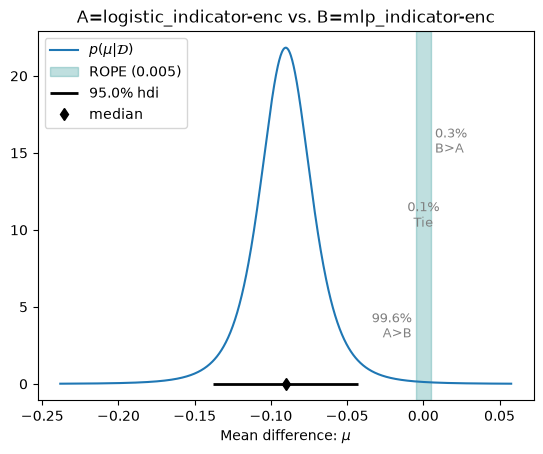

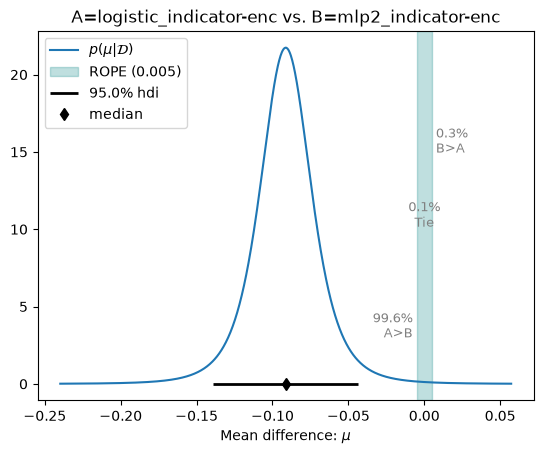

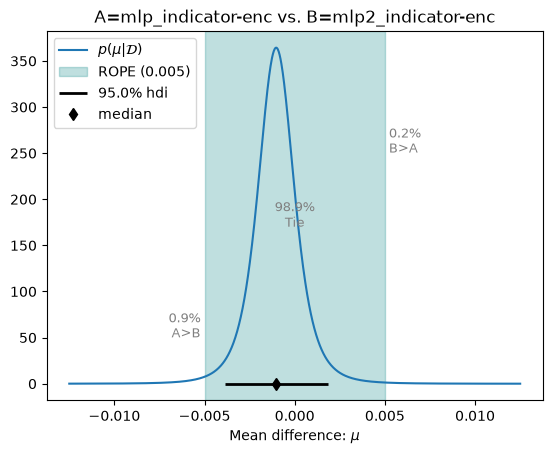

In [22]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

rope = 0.005

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [23]:

from pathlib import Path
import Project1.smlp as smlp
import Project1.smlp2 as smlp2

# Find saved checkpoints from your cross-validation
def find_checkpoints(model_name):
    folder = results_folder / model_name / "seed-0"

    checkpoints = sorted(
        path.with_suffix("")
        for path in folder.rglob("*.pt")
        if path.with_suffix(".json").exists()
    )

    if not checkpoints:
        raise FileNotFoundError(
            f"No saved model checkpoints found in {folder}"
        )

    return checkpoints


mlp_checkpoints = find_checkpoints("mlp_indicator-enc")
mlp2_checkpoints = find_checkpoints("mlp2_indicator-enc")

print("Original MLP checkpoints:")
for i, path in enumerate(mlp_checkpoints):
    print(i, path)

print("\nModified MLP checkpoints:")
for i, path in enumerate(mlp2_checkpoints):
    print(i, path)


Original MLP checkpoints:
0 results\mlp_indicator-enc\seed-0\fold-0\model
1 results\mlp_indicator-enc\seed-0\fold-1\model
2 results\mlp_indicator-enc\seed-0\fold-2\model
3 results\mlp_indicator-enc\seed-0\fold-3\model
4 results\mlp_indicator-enc\seed-0\fold-4\model

Modified MLP checkpoints:
0 results\mlp2_indicator-enc\seed-0\fold-0\model
1 results\mlp2_indicator-enc\seed-0\fold-1\model
2 results\mlp2_indicator-enc\seed-0\fold-2\model
3 results\mlp2_indicator-enc\seed-0\fold-3\model
4 results\mlp2_indicator-enc\seed-0\fold-4\model


In [24]:
# Select corresponding checkpoints from the same fold
fold = 0

mlp_model = smlp.load(
    str(mlp_checkpoints[fold]),
    device="cpu"
)

mlp2_model = smlp2.load2(
    str(mlp2_checkpoints[fold]),
    device="cpu"
)

mlp_model.eval()
mlp2_model.eval()

print("Both MLP models loaded successfully!")

Both MLP models loaded successfully!


In [25]:
# Log-linear
def logistic_predict(texts):
    return Project1.loglin.predict_probs(
        texts,
        logistic_model,
        token_indicator_encoder
    )

# Original MLP
def mlp_predict(texts):
    return Project1.smlp.predict_probs(
        texts,
        mlp_model,
        token_indicator_encoder
    )

# Modified MLP (two hidden layers)
def mlp2_predict(texts):
    return Project1.smlp2.predict_probs2(
        texts,
        mlp2_model,
        token_indicator_encoder
    )

# Models for LIME
models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

In [26]:
tweet_id = 157
test_text = dataset["test"][tweet_id]
print(test_text)
print("Original MLP:", mlp_predict(test_text))
print("Modified MLP:", mlp2_predict(test_text))
print("Log-linear:", logistic_predict(test_text))

{'text': 'What about in cases of rape', 'label': 2}
Original MLP: [[0.30356973 0.36801463 0.32841557]
 [0.2970166  0.3569385  0.3460449 ]]
Modified MLP: [[0.28542086 0.37666464 0.3379145 ]
 [0.2920606  0.37290153 0.33503783]]
Log-linear: [[0.46995272 0.27463356 0.25541372]
 [0.28037062 0.22161945 0.49800994]]



Tweet 1: Where is the childcare program @user which you said would be in place? #loneparents #7istooyoung
True class: against

--- Log-linear ---
Prediction: against
Probabilities: [0.2963 0.5851 0.1186]
Explanation: [(np.str_('7istooyoung'), 0.30172725605019063), (np.str_('loneparents'), 0.2959039148066089), (np.str_('place'), -0.24176267001466253), (np.str_('user'), -0.19218657734757844), (np.str_('would'), -0.15536551584353125), (np.str_('childcare'), 0.13142201766075975), (np.str_('be'), 0.08880067677894861), (np.str_('program'), -0.08842070576850615), (np.str_('in'), 0.06249661555772221), (np.str_('Where'), -0.05508143607363359)]


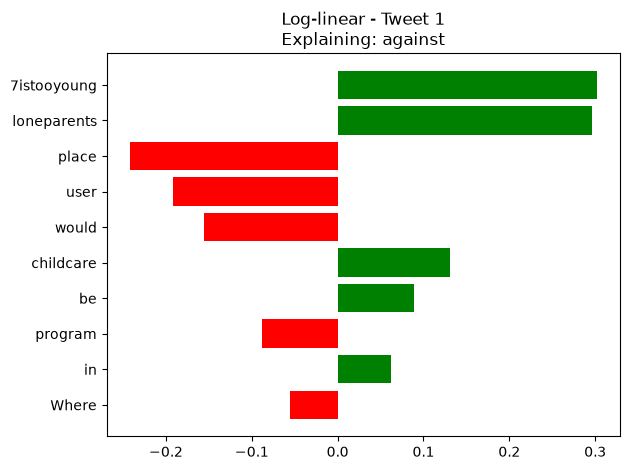


--- Original MLP ---
Prediction: against
Probabilities: [0.2773 0.502  0.2207]
Explanation: [(np.str_('loneparents'), 0.03772966107021748), (np.str_('childcare'), 0.0183684417026177), (np.str_('said'), 0.015690450886042265), (np.str_('Where'), 0.013355180674941859), (np.str_('the'), 0.012148809726569095), (np.str_('7istooyoung'), 0.011147061902067414), (np.str_('is'), 0.010261004161122219), (np.str_('be'), 0.008967504015082678), (np.str_('user'), 0.008271955801432486), (np.str_('you'), 0.006122428609945615)]


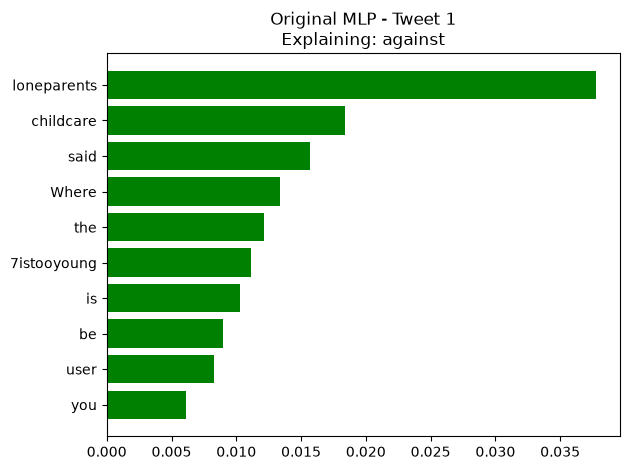


--- Modified MLP ---
Prediction: against
Probabilities: [0.2734 0.4307 0.2958]
Explanation: [(np.str_('7istooyoung'), 0.014316433638865691), (np.str_('said'), 0.014065828831497), (np.str_('loneparents'), 0.012713481972795907), (np.str_('user'), -0.008068949368900132), (np.str_('childcare'), 0.006700948393953524), (np.str_('Where'), -0.005925092482800259), (np.str_('place'), -0.0058282547499959375), (np.str_('the'), 0.004175408538068213), (np.str_('be'), 0.0036143183352921647), (np.str_('which'), 0.0032515066510237097)]


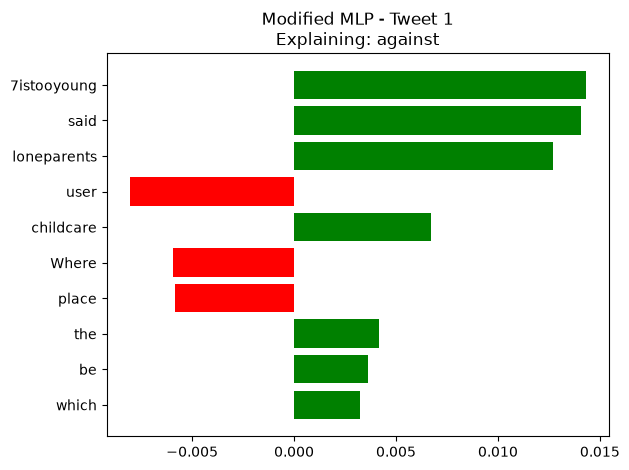


Tweet 8: Pray for the Navy yard. God please keep the casualties minimal.   #1A #2A #NRA #COS #CCOT #TGDN #PJNET  #WAKEUPAMERICA
True class: against

--- Log-linear ---
Prediction: against
Probabilities: [0.005 0.995 0.   ]
Explanation: [(np.str_('God'), 0.1426424810240551), (np.str_('please'), 0.11667618861832416), (np.str_('NRA'), 0.05191315180529643), (np.str_('TGDN'), -0.04982078483302895), (np.str_('casualties'), 0.04835446501090154), (np.str_('yard'), -0.040341434697774306), (np.str_('CCOT'), 0.03323195212476596), (np.str_('PJNET'), -0.019944324408305462), (np.str_('2A'), 0.018170681552681107), (np.str_('1A'), -0.015287439726227611)]


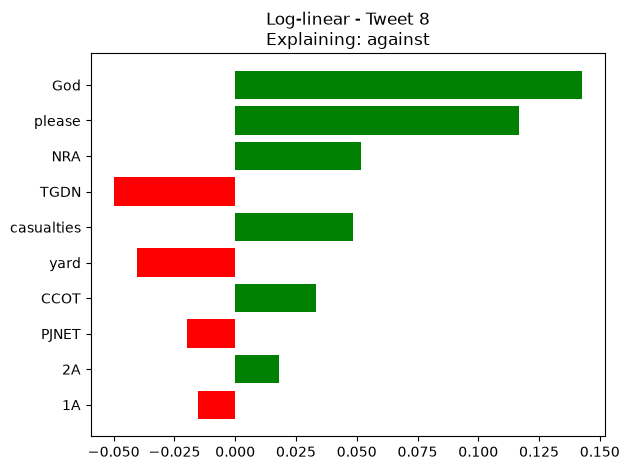


--- Original MLP ---
Prediction: against
Probabilities: [0.2913 0.5621 0.1466]
Explanation: [(np.str_('minimal'), 0.038778801429140204), (np.str_('WAKEUPAMERICA'), 0.027826964449597535), (np.str_('PJNET'), 0.027621348224931116), (np.str_('casualties'), 0.02040997631036354), (np.str_('please'), 0.01951870380392911), (np.str_('the'), 0.019464542278584872), (np.str_('God'), 0.019380651005106143), (np.str_('NRA'), 0.012165450219835441), (np.str_('COS'), 0.011341426269399336), (np.str_('keep'), -0.009073213221920975)]


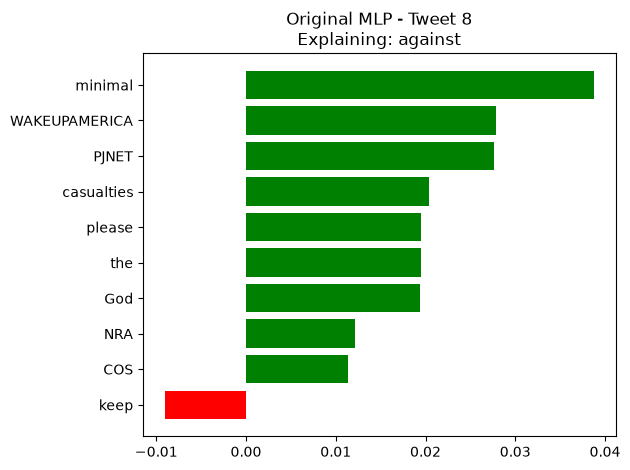


--- Modified MLP ---
Prediction: against
Probabilities: [0.2396 0.5215 0.2389]
Explanation: [(np.str_('Navy'), 0.0314466788754065), (np.str_('please'), 0.02706431265970867), (np.str_('God'), 0.014964961134436995), (np.str_('casualties'), 0.011777715258540947), (np.str_('TGDN'), 0.011065879862145536), (np.str_('PJNET'), 0.010254440835769102), (np.str_('COS'), 0.00949724137755291), (np.str_('CCOT'), 0.007893387559412142), (np.str_('WAKEUPAMERICA'), -0.0072142491290119294), (np.str_('the'), 0.006860100896130627)]


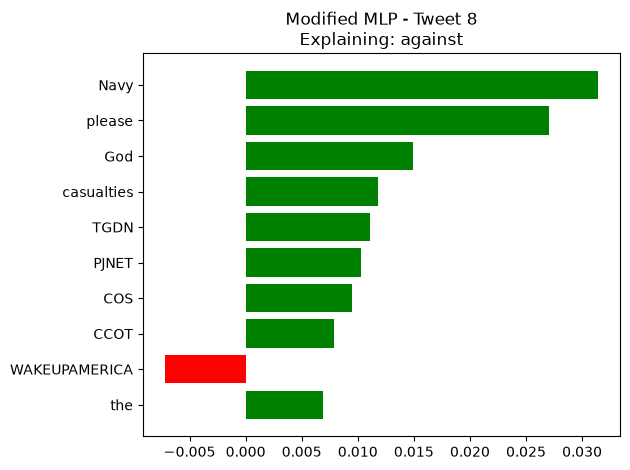


Tweet 157: What about in cases of rape
True class: favor

--- Log-linear ---
Prediction: favor
Probabilities: [0.2591 0.1603 0.5806]
Explanation: [(np.str_('What'), 0.1981120925149749), (np.str_('cases'), 0.17492084391008267), (np.str_('about'), -0.09833700008255375), (np.str_('in'), 0.047479514123776836), (np.str_('of'), -0.04667945927362483), (np.str_('rape'), 0.021309373183311896)]


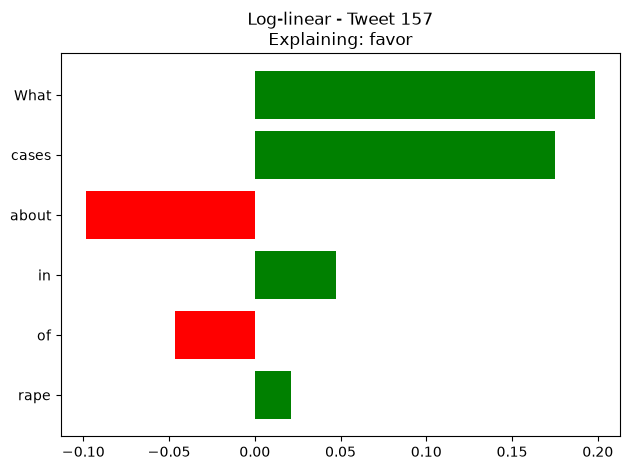


--- Original MLP ---
Prediction: against
Probabilities: [0.3068 0.3852 0.308 ]
Explanation: [(np.str_('about'), -0.01252810458266036), (np.str_('rape'), -0.01212278237560998), (np.str_('of'), -0.007346355720078889), (np.str_('What'), 0.003977691608810193), (np.str_('cases'), 0.002489232314082819), (np.str_('in'), -0.0010868877837673957)]


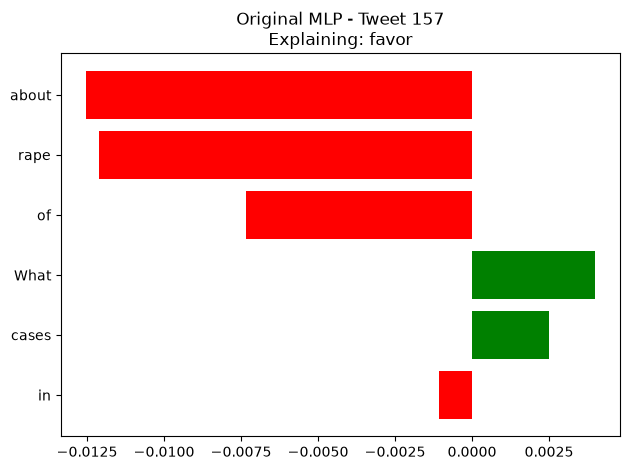


--- Modified MLP ---
Prediction: against
Probabilities: [0.2729 0.4092 0.3179]
Explanation: [(np.str_('rape'), -0.009316609707229207), (np.str_('of'), -0.008111996857888588), (np.str_('about'), -0.0056326684157578), (np.str_('in'), 0.004284783222027258), (np.str_('cases'), -0.0022796576279461916), (np.str_('What'), 0.0006834597572828225)]


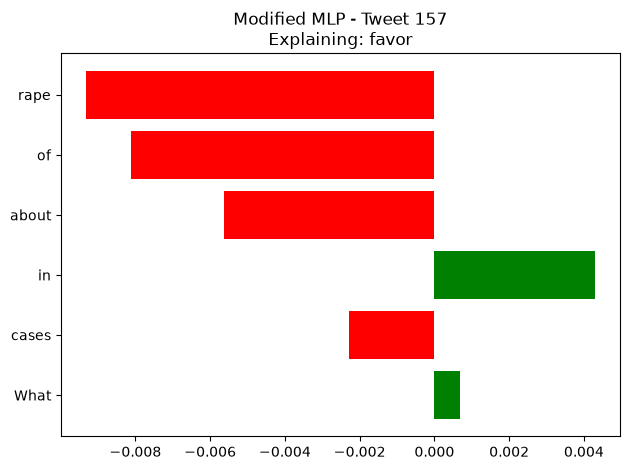

In [27]:
from lime.lime_text import LimeTextExplainer
import numpy as np
import matplotlib.pyplot as plt

class_names = dataset["train"].features["label"].names

explainer = LimeTextExplainer(
    class_names=class_names,
    random_state=42
)

models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

tweets = [1, 8, 157]

for tweet_id in tweets:

    example = dataset["test"][tweet_id]

    text = example["text"]
    true_label = int(example["label"])

    print(f"\n{'=' * 60}")
    print(f"Tweet {tweet_id}: {text}")
    print(f"True class: {class_names[true_label]}")

    for model_name, predict_fn in models.items():

        probabilities = predict_fn([text])[0]
        predicted_label = int(np.argmax(probabilities))

        # Explain the same target class across all models
        exp = explainer.explain_instance(
            text,
            predict_fn,
            num_features=10,
            num_samples=1000,
            labels=(true_label,)
        )

        print(f"\n--- {model_name} ---")
        print("Prediction:", class_names[predicted_label])
        print("Probabilities:", probabilities.round(4))
        print("Explanation:", exp.as_list(label=true_label))

        fig = exp.as_pyplot_figure(label=true_label)
        plt.title(
            f"{model_name} - Tweet {tweet_id}\n"
            f"Explaining: {class_names[true_label]}"
        )
        plt.tight_layout()
        plt.show()


In [28]:
# Collect cross-validation accuracy measurements
model_scores = {
    "Log-linear": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "MLP": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "Modified MLP": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

# Check the shapes
for name, scores in model_scores.items():
    print(name, scores.shape)

# Bayesian comparisons
results = []

for name_a, name_b in itertools.combinations(model_scores.keys(), 2):

    scores_a = np.asarray(model_scores[name_a], dtype=float)
    scores_b = np.asarray(model_scores[name_b], dtype=float)

    assert scores_a.shape == scores_b.shape, (
        "The models must have the same number of paired measurements."
    )

    posterior = Project1.analysis.BenavoliCorrelatedT(
        scores_a,
        scores_b,
        runs=1,  # Change if you used repeated cross-validation
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(0.005)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)

display(df.round(4))


Log-linear (5,)
MLP (5,)
Modified MLP (5,)


,Model A,Model B,P(A wins),P(Tie),P(B wins),Effect Size
0,Log-linear,MLP,0.9962,0.0013,0.0026,-5.2546
1,Log-linear,Modified MLP,0.9963,0.0012,0.0025,-5.2924
2,MLP,Modified MLP,0.0091,0.9888,0.0021,-1.0000


In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for sys_name, runs in classifiers.items():
    acc, prec, rec, f1 = [], [], [], []
    for r, run_data in enumerate(runs):
        for i, (fold, preds) in enumerate(run_data['predictions'].items()):
            gold = [y for _, y in my_cross_validation_sets[r][i]["validation"]]
            acc.append(accuracy_score(gold, preds))
            prec.append(precision_score(gold, preds, average="macro", zero_division=0))
            rec.append(recall_score(gold, preds, average="macro", zero_division=0))
            f1.append(f1_score(gold, preds, average="macro", zero_division=0))
    rows.append({
        "model": sys_name,
        "accuracy": np.mean(acc),
        "precision": np.mean(prec),
        "recall": np.mean(rec),
        "f1": np.mean(f1),
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df.round(4).to_string(index=False))

                 model  accuracy  precision  recall     f1
logistic_indicator-enc    0.5700     0.5450  0.5416 0.5419
     mlp_indicator-enc    0.4797     0.2931  0.3347 0.2186
    mlp2_indicator-enc    0.4787     0.1596  0.3333 0.2158
      logistic_bow-enc    0.5679     0.5433  0.5397 0.5404
           mlp_bow-enc    0.4815     0.4602  0.3373 0.2249
          mlp2_bow-enc    0.4787     0.1596  0.3333 0.2158
    logistic_tfidf-enc    0.5745     0.5699  0.4923 0.4940
         mlp_tfidf-enc    0.4787     0.1596  0.3333 0.2158
        mlp2_tfidf-enc    0.4787     0.1596  0.3333 0.2158


In [32]:
wlm = Project1.experiment.WrapperForLoglinearModel(token_indicator_encoder, Project1.loglin.load("results/logistic_indicator-enc/seed-0/fold-0/model"))
wlm(dataset["test"]["text"][0])

array([0.26562078, 0.69138598, 0.04299324])

In [34]:
agnews_outcome_space = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
print(agnews_outcome_space)

0: against, 1: neutral, 2: in favor


In [38]:
class DecisionRule:
    """
    This class outputs a decision by searching through a given pmf via the method __call__.
    """

    def __call__(self, pmf: 'np.array') -> int:
        """Return the chosen outcome (int) out of those available in the support of the pmf"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class MostProbableClass(DecisionRule):
    """
    The 'most probable class' decision rule.
    """
    
    def __call__(self, pmf: 'np.array') -> int:
        return np.argmax(pmf)

D = MostProbableClass()

In [40]:
mc_one = Project1.clslib.MajorityVoteClassifier(agnews_outcome_space, [wlm], MostProbableClass())

mc_all = Project1.experiment.ensemble_loglin(agnews_outcome_space, token_indicator_encoder, MostProbableClass(), 'logistic_indicator-enc', my_seeds, num_folds, results_folder)

In [42]:
preds_one = [agnews_outcome_space.index(mc_one(text)) for text in dataset["test"]["text"]]
preds_all = [agnews_outcome_space.index(mc_all(text)) for text in dataset["test"]["text"]]

In [43]:
from sklearn.metrics import classification_report
print("Single model")
print(classification_report(dataset["test"]["label"], preds_one, target_names=agnews_outcome_space.names))
print("Ensemble")
print(classification_report(dataset["test"]["label"], preds_all, target_names=agnews_outcome_space.names))

Single model
              precision    recall  f1-score   support

     against       0.32      0.39      0.35       230
     neutral       0.72      0.60      0.65       715
    in favor       0.43      0.53      0.47       304

    accuracy                           0.54      1249
   macro avg       0.49      0.51      0.49      1249
weighted avg       0.57      0.54      0.55      1249

Ensemble
              precision    recall  f1-score   support

     against       0.35      0.43      0.38       230
     neutral       0.74      0.62      0.67       715
    in favor       0.45      0.54      0.49       304

    accuracy                           0.57      1249
   macro avg       0.51      0.53      0.52      1249
weighted avg       0.60      0.57      0.58      1249

